# TVD vs Work-per-code (grouped fits)

Goal: run a single random permutation scan, then analyze correlations:
- overall trend (all points)
- per-`codes_used` trend (separate linear fits + correlations)

This notebook assumes the scan dataframe includes:
`logical_total_variation_distance`, `codes_used`, `one_qubit_gates`, `two_qubit_gates`, `total_gates`, `circuit_depth`.


In [1]:
import os
import sys
from pathlib import Path

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns
from scipy.stats import pearsonr, spearmanr
from qiskit.circuit.random import random_clifford_circuit

# Ensure repo imports work when notebook is run from anywhere.
REPO_ROOT = Path.cwd()
while REPO_ROOT.name and not (REPO_ROOT / "pipeline").exists():
    if REPO_ROOT.parent == REPO_ROOT:
        break
    REPO_ROOT = REPO_ROOT.parent

if str(REPO_ROOT) not in sys.path:
    sys.path.append(str(REPO_ROOT))

os.environ.setdefault("MPLBACKEND", "Agg")
os.environ.setdefault("MPLCONFIGDIR", str(REPO_ROOT / ".mplconfig"))

from pipeline import PipelineConfig, run_random_scan
from simulator.config_presets import ScaledSimulator

sns.set_theme(style="whitegrid")
plt.rcParams.update({"figure.figsize": (9, 5.5)})


## 1) Run one scan (once)

Tune these parameters as needed. This cell is the expensive part.

In [7]:
# --- Experiment parameters ---
qubits = 10
num_gates = 200
permutations = 250
repetitions = 50_000
seed = 11
distance_scalar = 1.0

# Work weights (ratio matters most for rank-based metrics).
w1 = 1.0
w2 = 13.0

program_circuit = random_clifford_circuit(
    qubits,
    num_gates=num_gates,
    gates=["h", "x", "z", "s", "cx", "cz"],
    seed=seed,
)
program_circuit.measure_all()

sim_cfg = (
    ScaledSimulator(alpha=0.5, repetitions=repetitions, seed=seed)
    .with_distance_based_noise(distance_scalar=distance_scalar)
    .with_stim()
)
pipeline_cfg = PipelineConfig(sim_config=sim_cfg, verbose=False, save=False, seed=seed)

record = run_random_scan(program_circuit=program_circuit, m=permutations, config=pipeline_cfg)
df = record.dataframe.df.copy()
df.head(3)


Shots:   0%|          | 0/50000 [00:00<?, ?shot/s]

Simulating circuits:   0%|          | 0/250 [00:00<?, ? sim/s]

Shots:   0%|          | 0/50000 [00:00<?, ?shot/s]

Shots:   0%|          | 0/50000 [00:00<?, ?shot/s]

Shots:   0%|          | 0/50000 [00:00<?, ?shot/s]

...

Shots:   0%|          | 0/50000 [00:00<?, ?shot/s]

Shots:   0%|          | 0/50000 [00:00<?, ?shot/s]

Shots:   0%|          | 0/50000 [00:00<?, ?shot/s]

[(8, 1), (7, 1), (4, 1), (9, 1), (9, 0), (1, 1), (4, 0), (3, 0), (8, 0), (7, 0)]


,permutation,perm_key,codes_used,fidelity,logical_error_rate,postselected,ideal_dist,noisy_dist,postselected_dist,logical_fidelity,logical_selection_rate,selection_rate_overall,logical_total_variation_distance,gate_count,total_gates,one_qubit_gates,two_qubit_gates,circuit_depth,contains_faults,fault_tolerant
0,"[(8, 1), (7, 1), (4, 1), (9, 1), (9, 0), (1, 1...","((8, 1), (7, 1), (4, 1), (9, 1), (9, 0), (1, 1...",6,0.861442,0.138558,True,None,{'00 11 00 10 00 00 00 00 00 00 1111 1000 0000...,"{'0110101011': 0.0023937761819269898, '0001010...",0.861442,0.03342,0.0,0.324662,"{'H': 197, 'CX': 226, 'BARRIER': 22, 'CZ': 259...",1028,389,557,264,False,False
1,"[(3, 0), (7, 0), (6, 1), (1, 1), (6, 0), (8, 1...","((3, 0), (7, 0), (6, 1), (1, 1), (6, 0), (8, 1...",7,0.894153,0.105847,True,None,{'10 00 00 00 00 00 00 00 00 0011 0000 0110 11...,"{'1001110101': 0.0010362694300518134, '1111110...",0.894153,0.03860,0.0,0.287899,"{'H': 182, 'CX': 215, 'BARRIER': 20, 'SWAP': 7...",960,361,525,211,False,False
2,"[(6, 0), (5, 0), (8, 1), (1, 1), (2, 1), (0, 1...","((6, 0), (5, 0), (8, 1), (1, 1), (2, 1), (0, 1...",8,0.894082,0.105918,True,None,{'00 01 00 00 00 10 10 00 00 1111 0001 0011 11...,"{'1011111000': 0.0009564801530368245, '0011101...",0.894082,0.04182,0.0,0.292951,"{'H': 171, 'CX': 215, 'BARRIER': 20, 'SWAP': 8...",944,343,527,162,False,False


## 2) Feature engineering

Define the baseline metrics and the combined metric.

In [8]:
required = {
    "logical_total_variation_distance",
    "codes_used",
    "one_qubit_gates",
    "two_qubit_gates",
    "total_gates",
    "circuit_depth",
}
missing = required - set(df.columns)
if missing:
    raise KeyError(f"Missing columns in scan dataframe: {sorted(missing)}")

for col in required:
    df[col] = pd.to_numeric(df[col], errors="coerce")

df = df.dropna(subset=list(required)).reset_index(drop=True)
df = df[(df["codes_used"] > 0) & (df["total_gates"] > 0)].reset_index(drop=True)

df["n2_per_code"] = df["two_qubit_gates"] / df["codes_used"]
df["work_per_code"] = (w1 * df["one_qubit_gates"] + w2 * df["two_qubit_gates"]) / df["codes_used"]
df["depth_over_total_gates"] = df["circuit_depth"] / df["total_gates"]
df["work_depth_score"] = df["work_per_code"] * df["depth_over_total_gates"]

df[["codes_used", "one_qubit_gates", "two_qubit_gates", "circuit_depth", "work_per_code", "work_depth_score"]].describe()


,codes_used,one_qubit_gates,two_qubit_gates,circuit_depth,work_per_code,work_depth_score
count,250.000000,250.000000,250.00000,250.000000,250.000000,250.000000
mean,7.676000,362.500000,539.42800,202.404000,973.241635,202.656592
std,0.813431,14.659797,13.93231,28.747355,121.600729,48.282682
min,6.000000,329.000000,497.00000,130.000000,713.500000,98.570670
25%,7.000000,352.000000,530.25000,182.250000,904.406250,169.161524
50%,8.000000,361.000000,539.00000,201.500000,931.750000,193.805547
75%,8.000000,371.750000,548.00000,221.000000,1057.357143,233.537652
max,10.000000,414.000000,583.00000,305.000000,1330.666667,379.302181


## 3) Correlations: overall + per-group

In [9]:
def corr_summary(x: pd.Series, y: pd.Series) -> dict:
    x = np.asarray(x, dtype=float)
    y = np.asarray(y, dtype=float)
    mask = np.isfinite(x) & np.isfinite(y)
    x = x[mask]
    y = y[mask]
    if len(x) < 2:
        return {"n": len(x), "pearson": np.nan, "pearson_p": np.nan, "spearman": np.nan, "spearman_p": np.nan}
    pr = pearsonr(x, y)
    sr = spearmanr(x, y)
    return {"n": len(x), "pearson": float(pr.statistic), "pearson_p": float(pr.pvalue), "spearman": float(sr.statistic), "spearman_p": float(sr.pvalue)}


def print_corr(label: str, x: pd.Series, y: pd.Series) -> None:
    s = corr_summary(x, y)
    print(
        f"{label}: n={s['n']} | pearson={s['pearson']:.3f} (p={s['pearson_p']:.2e}) | "
        f"spearman={s['spearman']:.3f} (p={s['spearman_p']:.2e})"
    )


y = df["logical_total_variation_distance"]
print_corr("overall: tvd vs n2_per_code", df["n2_per_code"], y)
print_corr(f"overall: tvd vs work_per_code (w1={w1:g}, w2={w2:g})", df["work_per_code"], y)
print_corr("overall: tvd vs work_depth_score", df["work_depth_score"], y)

rows = []
for codes_used, g in df.groupby("codes_used"):
    s = corr_summary(g["work_per_code"], g["logical_total_variation_distance"])
    rows.append({"codes_used": int(codes_used), **s})
group_corr = pd.DataFrame(rows).sort_values("codes_used")
group_corr


overall: tvd vs n2_per_code: n=250 | pearson=0.207 (p=9.72e-04) | spearman=0.298 (p=1.67e-06)
overall: tvd vs work_per_code (w1=1, w2=13): n=250 | pearson=0.206 (p=1.07e-03) | spearman=0.298 (p=1.54e-06)
overall: tvd vs work_depth_score: n=250 | pearson=0.163 (p=1.00e-02) | spearman=0.134 (p=3.49e-02)


,codes_used,n,pearson,pearson_p,spearman,spearman_p
0,6,18,0.767896,1.983216e-04,0.779154,1.384760e-04
1,7,81,0.805641,1.201209e-19,0.793199,1.076182e-18
2,8,116,0.802209,2.696860e-27,0.770644,4.739305e-24
3,9,34,0.778643,5.883077e-08,0.767150,1.208195e-07
4,10,1,NaN,NaN,NaN,NaN


## 4) One plot: overall fit + per-group fits

This makes it easy to see strong within-group trends even if the overall trend is weaker due to group offsets.

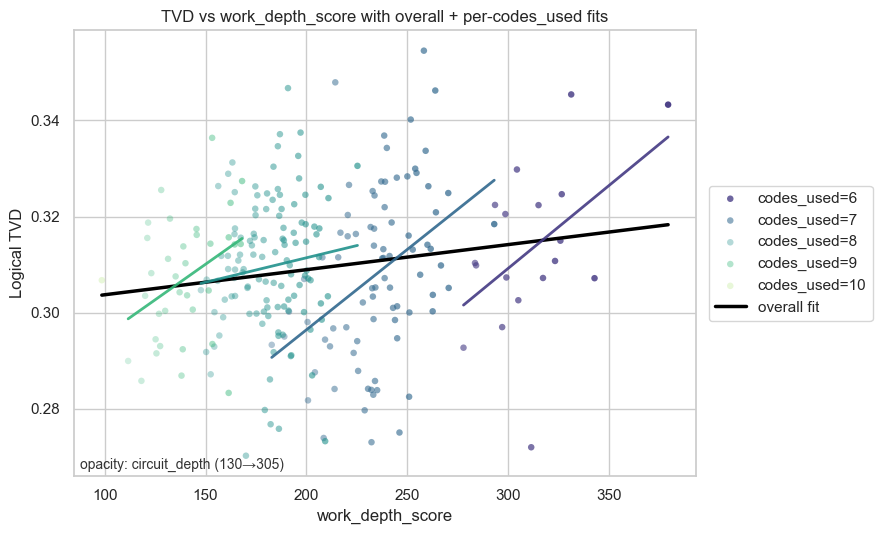

In [ ]:
def fit_line(x: np.ndarray, y: np.ndarray):
    x = np.asarray(x, dtype=float)
    y = np.asarray(y, dtype=float)
    mask = np.isfinite(x) & np.isfinite(y)
    x = x[mask]
    y = y[mask]
    if len(x) < 2:
        return None
    slope, intercept = np.polyfit(x, y, deg=1)
    return float(slope), float(intercept)


xcol = "work_per_code"  # change to "n2_per_code" or "work_depth_score" to compare
# xcol = "work_depth_score"  # change to "n2_per_code" or "work_depth_score" to compare
ycol = "logical_total_variation_distance"
groupcol = "codes_used"
depthcol = "circuit_depth"  # encoded as point opacity

alpha_min = 0.20
alpha_max = 0.95
depth_min = float(df[depthcol].min())
depth_max = float(df[depthcol].max())

fig, ax = plt.subplots(facecolor="white")
ax.set_facecolor("white")

palette = sns.color_palette("viridis", n_colors=df[groupcol].nunique())
codes_sorted = sorted(df[groupcol].unique())
color_map = {c: palette[i] for i, c in enumerate(codes_sorted)}

# Scatter by group (color=codes_used, opacity=depth)
for c in codes_sorted:
    g = df[df[groupcol] == c]
    depths = g[depthcol].to_numpy(dtype=float)
    if depth_max > depth_min:
        alphas = alpha_min + (alpha_max - alpha_min) * (depths - depth_min) / (depth_max - depth_min)
    else:
        alphas = np.full_like(depths, (alpha_min + alpha_max) / 2.0)
    alphas = np.clip(alphas, alpha_min, alpha_max)
    colors = [(*color_map[c], float(a)) for a in alphas]
    ax.scatter(g[xcol], g[ycol], s=22, color=colors, edgecolors="none", label=f"codes_used={int(c)}")

# Overall fit
overall_fit = fit_line(df[xcol].to_numpy(), df[ycol].to_numpy())
if overall_fit is not None:
    slope, intercept = overall_fit
    xs = np.linspace(df[xcol].min(), df[xcol].max(), 300)
    ax.plot(xs, slope * xs + intercept, color="black", linewidth=2.5, label="overall fit")

# Per-group fits
for c in codes_sorted:
    g = df[df[groupcol] == c]
    group_fit = fit_line(g[xcol].to_numpy(), g[ycol].to_numpy())
    if group_fit is None:
        continue
    slope, intercept = group_fit
    xs = np.linspace(g[xcol].min(), g[xcol].max(), 80)
    ax.plot(xs, slope * xs + intercept, color=color_map[c], linewidth=2.0, alpha=0.9)

ax.set_xlabel(xcol)
ax.set_ylabel("Logical TVD")
ax.set_title(f"TVD vs {xcol} with overall + per-codes_used fits")
ax.text(
    0.01,
    0.01,
    f"opacity: {depthcol} ({depth_min:.0f}→{depth_max:.0f})",
    transform=ax.transAxes,
    ha="left",
    va="bottom",
    fontsize=10,
    color="black",
    alpha=0.8,
)

ax.legend(bbox_to_anchor=(1.02, 0.5), loc="center left", borderaxespad=0)
plt.tight_layout()
plt.show()


## 5) Optional: slope table per group

In [18]:
rows = []
for c, g in df.groupby("codes_used"):
    fit = fit_line(g[xcol].to_numpy(), g[ycol].to_numpy())
    if fit is None:
        continue
    slope, intercept = fit
    corr = corr_summary(g[xcol], g[ycol])
    rows.append(
        {
            "codes_used": int(c),
            "n": corr["n"],
            "slope": slope,
            "intercept": intercept,
            "pearson": corr["pearson"],
            "spearman": corr["spearman"],
        }
    )

pd.DataFrame(rows).sort_values("codes_used")


,codes_used,n,slope,intercept,pearson,spearman
0,6,18,0.000345,0.205768,0.482850,0.389061
1,7,81,0.000334,0.229607,0.383106,0.420528
2,8,116,0.000102,0.291095,0.117806,0.113266
3,9,34,0.000296,0.265689,0.355679,0.372345
